# Praktikum 2 - Klasifikasi Data Iris dengan Keras

**Nama:** Agus
**NIM:** 244107020049

[Sumber modul](https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js13-artificial-neural-network-ann-dan-evaluasi-classifier/praktikum-2)

Kode utama mengikuti modul: Iris, one-hot, split 80:20, Dense 10 ReLU, Dense 8 ReLU, softmax, Adam, 50 epoch, dan batch 8. Penyesuaiannya:
* `OneHotEncoder(sparse=False)` diganti `sparse_output=False`. Argumen `sparse` dihapus pada scikit-learn 1.4 sehingga kode lama menghasilkan `TypeError`.
* `input_shape` pada Dense dipindah ke layer `Input` sesuai Keras 3. Arsitekturnya tetap sama.
* `random_state=42` ditambahkan pada split agar hasilnya reprodusibel.

In [1]:
import sys
import numpy as np
import tensorflow as tf
tf.keras.utils.set_random_seed(42)
print("Kernel:", sys.executable)
print("TensorFlow:", tf.__version__)

Kernel: /Users/jergal/College/machine-learning-smt-5/.venv/bin/python
TensorFlow: 2.21.0


## Langkah 1-5 - Import, load dataset, bangun model, kompilasi dan latih, evaluasi (kode modul)

In [2]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
import tensorflow as tf

# Load dataset
iris = load_iris()
X = iris.data
y = iris.target.reshape(-1, 1)

# One-hot encoding
encoder = OneHotEncoder(sparse_output=False)
y = encoder.fit_transform(y)

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Bangun model
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(4,)),
    tf.keras.layers.Dense(10, activation='relu'),
    tf.keras.layers.Dense(8, activation='relu'),
    tf.keras.layers.Dense(3, activation='softmax')
])

# Kompilasi
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Latih model
history = model.fit(X_train, y_train, epochs=50, batch_size=8, verbose=2)

# Evaluasi
loss, acc = model.evaluate(X_test, y_test)
print(f"Akurasi: {acc}")

Epoch 1/50


15/15 - 0s - 17ms/step - accuracy: 0.3417 - loss: 1.8659


Epoch 2/50


15/15 - 0s - 749us/step - accuracy: 0.3417 - loss: 1.5883


Epoch 3/50


15/15 - 0s - 768us/step - accuracy: 0.3417 - loss: 1.3693


... (93 outputs left out)

15/15 - 0s - 636us/step - accuracy: 0.9667 - loss: 0.2183


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.9667 - loss: 0.2103

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.9667 - loss: 0.2103


Akurasi: 0.9666666388511658


              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     1.0000    0.8889    0.9412         9
   virginica     0.9167    1.0000    0.9565        11

    accuracy                         0.9667        30
   macro avg     0.9722    0.9630    0.9659        30
weighted avg     0.9694    0.9667    0.9664        30



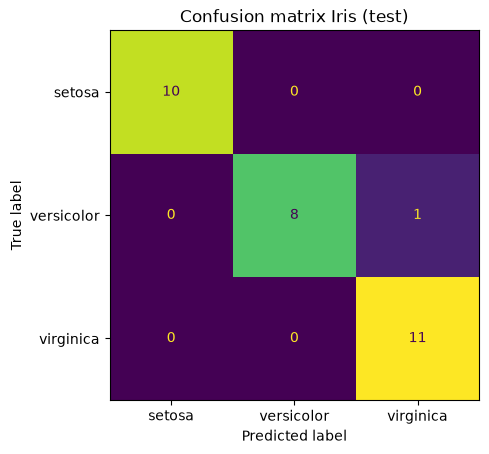

In [3]:
import numpy as np, matplotlib.pyplot as plt
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
y_pred = model.predict(X_test, verbose=0).argmax(1); y_true = y_test.argmax(1)
print(classification_report(y_true, y_pred, target_names=iris.target_names, digits=4))
ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=iris.target_names, colorbar=False)
plt.title('Confusion matrix Iris (test)'); plt.show()

## Tugas 2 dan Tugas 3

* **Tugas 2:** ubah jumlah neuron hidden layer dan bandingkan akurasinya dengan konfigurasi awal (10-8).
* **Tugas 3:** bandingkan Sigmoid dan ReLU pada Iris, lalu catat perbedaan loss dan akurasi.

Data uji Iris hanya 30 sampel, sehingga satu kesalahan menggeser akurasi 3,3 poin. Karena itu setiap konfigurasi diulang pada
**5 seed**. Setiap seed memberi split dan bobot awal yang berbeda. Hasil dilaporkan sebagai rata-rata dan simpangan baku.
Pengaturan lain sama dengan kode modul: tanpa scaling, Adam, 50 epoch, dan batch 8.

In [4]:
import pandas as pd

def run(hidden=(10, 8), activation='relu', seed=42, epochs=50):
    tf.keras.utils.set_random_seed(seed)
    Xtr, Xte, ytr, yte = train_test_split(iris.data, encoder.transform(iris.target.reshape(-1, 1)), test_size=0.2, random_state=seed)
    m = tf.keras.Sequential([tf.keras.layers.Input(shape=(4,))]
                            + [tf.keras.layers.Dense(h, activation=activation) for h in hidden]
                            + [tf.keras.layers.Dense(3, activation='softmax')])
    m.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    h = m.fit(Xtr, ytr, epochs=epochs, batch_size=8, verbose=0)
    loss, acc = m.evaluate(Xte, yte, verbose=0)
    return {'params': m.count_params(), 'train_loss': h.history['loss'][-1], 'test_loss': loss, 'test_acc': acc}, h.history['loss']

seeds = [0, 1, 2, 3, 42]
def experiment(configs):
    rows, curves = [], {}
    for name, kw in configs.items():
        for s in seeds:
            r, curve = run(seed=s, **kw)
            rows.append({'konfigurasi': name, 'seed': s, **r})
            if s == 42: curves[name] = curve
    df = pd.DataFrame(rows)
    return df.groupby('konfigurasi', sort=False).agg(
        params=('params', 'first'), train_loss=('train_loss', 'mean'),
        test_loss=('test_loss', 'mean'), test_loss_std=('test_loss', 'std'),
        test_acc=('test_acc', 'mean'), test_acc_std=('test_acc', 'std'), test_acc_min=('test_acc', 'min')).round(4), curves

In [5]:
t2, curves2 = experiment({
    'awal 10-8 (modul)': dict(hidden=(10, 8)),
    'kecil 4-3': dict(hidden=(4, 3)),
    'sedang 32-16': dict(hidden=(32, 16)),
    'besar 64-32': dict(hidden=(64, 32)),
})
t2

,params,train_loss,test_loss,test_loss_std,test_acc,test_acc_std,test_acc_min
konfigurasi,,,,,,,
awal 10-8 (modul),165,0.2614,0.2583,0.1615,0.9267,0.1116,0.7333
kecil 4-3,47,0.8036,0.8091,0.2936,0.5733,0.3122,0.2000
sedang 32-16,739,0.1076,0.0896,0.0109,0.9933,0.0149,0.9667
besar 64-32,2499,0.0886,0.0723,0.0146,0.9933,0.0149,0.9667


In [6]:
t3, curves3 = experiment({
    'ReLU 10-8 (modul)': dict(hidden=(10, 8), activation='relu'),
    'Sigmoid 10-8': dict(hidden=(10, 8), activation='sigmoid'),
    'ReLU 64-32': dict(hidden=(64, 32), activation='relu'),
    'Sigmoid 64-32': dict(hidden=(64, 32), activation='sigmoid'),
})
t3

,params,train_loss,test_loss,test_loss_std,test_acc,test_acc_std,test_acc_min
konfigurasi,,,,,,,
ReLU 10-8 (modul),165,0.2614,0.2583,0.1615,0.9267,0.1116,0.7333
Sigmoid 10-8,165,0.5616,0.5519,0.0472,0.7600,0.1278,0.6333
ReLU 64-32,2499,0.0886,0.0723,0.0146,0.9933,0.0149,0.9667
Sigmoid 64-32,2499,0.1849,0.1753,0.0358,0.9800,0.0183,0.9667


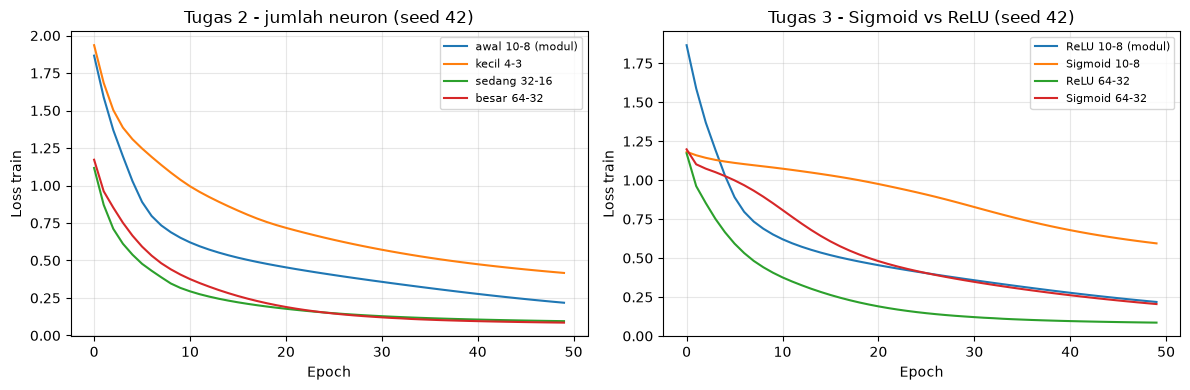

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name, c in curves2.items(): ax[0].plot(c, label=name)
for name, c in curves3.items(): ax[1].plot(c, label=name)
ax[0].set_title('Tugas 2 - jumlah neuron (seed 42)'); ax[1].set_title('Tugas 3 - Sigmoid vs ReLU (seed 42)')
for a in ax: a.set_xlabel('Epoch'); a.set_ylabel('Loss train'); a.legend(fontsize=8); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## Analisis Tugas 2 dan Tugas 3

**Kode modul (seed 42):** akurasi test 96,67% (29/30). Satu versicolor diprediksi virginica, pasangan kelas yang memang tumpang tindih pada data Fisher (1936).

**Tugas 2 - jumlah neuron (rata-rata 5 seed):**

| Hidden | Parameter | Loss test | Akurasi test | Akurasi minimum |
| --- | --- | --- | --- | --- |
| 4-3 | 47 | 0,809 | 57,3% ± 31,2 | 20,0% |
| 10-8 (modul) | 165 | 0,258 | 92,7% ± 11,2 | 73,3% |
| 32-16 | 739 | 0,090 | **99,3% ± 1,5** | 96,7% |
| 64-32 | 2.499 | **0,072** | **99,3% ± 1,5** | 96,7% |

Menambah neuron menurunkan loss dan, yang paling penting, menurunkan **variansi** antar-seed. Konfigurasi 4-3 kadang tidak belajar sama sekali (akurasi 20%) karena neuron ReLU yang sedikit mudah mati, dan 50 epoch tidak cukup untuk keluar dari kondisi itu. Konfigurasi modul 10-8 rata-rata baik, tetapi satu seed hanya mencapai 73,3%. Dari 32-16 ke atas hasilnya stabil, dan penambahan ke 64-32 hanya memperbaiki loss. Jadi untuk Iris dengan 4 fitur, kapasitas sekitar 32-16 sudah cukup. Overfitting tidak muncul karena loss test justru sedikit lebih rendah daripada loss train.

**Tugas 3 - Sigmoid vs ReLU (rata-rata 5 seed):**

| Konfigurasi | Loss train | Loss test | Akurasi test |
| --- | --- | --- | --- |
| ReLU 10-8 | 0,261 | 0,258 | 92,7% |
| Sigmoid 10-8 | 0,562 | 0,552 | 76,0% |
| ReLU 64-32 | **0,089** | **0,072** | **99,3%** |
| Sigmoid 64-32 | 0,185 | 0,175 | 98,0% |

Pada ukuran jaringan yang sama, ReLU selalu menghasilkan loss sekitar 2 kali lebih rendah dalam 50 epoch. Sigmoid berada di daerah jenuh karena input Iris tidak distandarisasi (nilai 0,1-7,9 cm), sehingga turunannya kecil (maksimum 0,25) dan pembaruan bobot lambat. Glorot & Bengio (2010) menunjukkan bahwa sigmoid mudah jenuh dan memperlambat pelatihan, sedangkan Glorot dkk. (2011) menunjukkan bahwa ReLU menghasilkan gradien yang lebih kuat dan representasi *sparse*. Dengan jaringan yang lebih lebar (64-32), selisih akurasinya mengecil (98,0% vs 99,3%), tetapi loss sigmoid tetap lebih tinggi. Artinya, keyakinan prediksi model sigmoid lebih rendah. LeCun dkk. (1998, *Efficient BackProp*) juga menganjurkan normalisasi input agar fungsi aktivasi bekerja di daerah yang tidak jenuh.

## Rujukan

1. Fisher, R. A. (1936). The use of multiple measurements in taxonomic problems. *Annals of Eugenics*, 7(2), 179-188. https://doi.org/10.1111/j.1469-1809.1936.tb02137.x
2. Glorot, X., & Bengio, Y. (2010). Understanding the difficulty of training deep feedforward neural networks. *Proceedings of AISTATS*, PMLR 9, 249-256.
3. Glorot, X., Bordes, A., & Bengio, Y. (2011). Deep sparse rectifier neural networks. *Proceedings of AISTATS*, PMLR 15, 315-323.
4. Kingma, D. P., & Ba, J. (2015). Adam: A method for stochastic optimization. *International Conference on Learning Representations (ICLR)*. https://arxiv.org/abs/1412.6980
5. LeCun, Y., Bottou, L., Orr, G. B., & Müller, K.-R. (1998). Efficient BackProp. Dalam *Neural Networks: Tricks of the Trade* (LNCS 1524, hlm. 9-50). Springer. https://doi.org/10.1007/3-540-49430-8_2